# HPCQC Hands-on
## CPU, GPU and QPU backends with CUDA-Q

This notebook shows **how hybrid classical-quantum exeuction and dataflow works between classical CPU, GPU, and QPU with CUDA-Q** on the LRZ HPCQC system. It is an infrastructure demo, not a quantum algorithm. The circuit is simply GHZ.

```
  host (CPU)                quantum backends
 ┌──────────────┐  sample  ┌──────────────────────────┐
 │              │ ───────▶ │ CPU backend              │  Case 1
 │              │ ◀─────── │ qpp-cpu cudaq-sim.       │
 │              │  counts  └──────────────────────────┘
 │              │
 │              │  sample  ┌──────────────────────────┐
 │              │ ───────▶ │ GPU backend              │  Case 2
 │              │ ◀─────── │ nvidia cudaq-sim.        │
 │              │  counts  └──────────────────────────┘
 │ list[float]  │
 │ counts       │  sample  ┌──────────────────────────┐
 │              │ ───────▶ │ multi-QPU backend run on │  Case 3
 │              │ ◀─────── │ multi-GPU, mqpu cudaq-sim│
 │              │  counts  └──────────────────────────┘
 │              │
 │              │  sample  ┌──────────────────────────┐
 │              │ ───────▶ │ IQM QPU backend          │  Case 4
 │              │ ◀─────── │ iqm (LRZ HPC-QC)         │
 └──────────────┘  counts  └──────────────────────────┘
```

The host (CPU) always holds the parameters and the results. The four cases differ only in where the kernel runs, selected with `cudaq.set_target(...)`. Each run is timed.

## Setup

If running on LRZ system, the cells that start with `%%beast` are magic cells to submit SLURM jobs in background for getting access to GPU or QPU at LRZ. They don't run in this notebook: each one is submitted as a Slurm job to the HPCQC cluster, and `NAME.result()` in the next cell waits for its output.

If running on Colab, the notebook will skip the magic cells.

In [1]:
# Install the packages (Colab only)
import sys
if "google.colab" in sys.modules:
    import os
    import subprocess

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "cudaq", "iqm-cortex-cli", "matplotlib", "numpy", "cudaq-qec"])
    # the cells write their results here
    os.makedirs("output", exist_ok=True)
    # install the utility function to skip the beast cells if running in colab
    REPO = "/content/sc26_quantum_tutorial"
    if not os.path.exists(REPO):
        !git clone -q https://github.com/zohimchandani/sc26_quantum_tutorial.git {REPO}
    sys.path.insert(0, f"{REPO}/util")
    import colab_skip_beast_cells

    # set the IQM token and server URL
    os.environ["IQM_TOKEN"] = "qF8rj+26ctdJavXVpyPRCa482mB95s1tyB+rhVarvDoBod/PhhJ0MIbTRwF8WfZM"
    os.environ.setdefault("IQM_SERVER_URL", "https://cocos.resonance.meetiqm.com/garnet:timeslot")
    # Uncomment the next line if you are running on Colab but do not have a timeslot reserved
    # os.environ["IQM_SERVER_URL"]= "https://cocos.resonance.meetiqm.com/garnet"

    print("✅ Installation complete. If the runtime restarted, continue from the next cell.")

✅ Installation complete. If the runtime restarted, continue from the next cell.


In [2]:
import os
import sys
import time
import json
import socket
import cupy as cp
import numpy as np
import matplotlib.pyplot as plt

import cudaq
from cudaq import spin

/usr/local/lib/python3.13/dist-packages/cudaq/__init__.py:260: UserWarning: cudaq-logical is in preview. Its APIs, behavior, and documentation may change substantially in upcoming versions.
  from . import logical  # noqa: F401
/tmp/ipykernel_745/1042662038.py:10: FutureWarning: The CUDA-Q `sample` and `observe` algorithmic primitives will change in a future release. Existing code may require updates. See https://nvidia.github.io/cuda-quantum/latest/using/migration/upcoming_changes.html for details.
  import cudaq


## Kernels and helpers

`GHZ` is the demo kernel. It allocates a `cudaq.qvector` of `n` qubits, applies `h` to the first qubit to create a superposition, and then a chain of `cx` gates (`x.ctrl` in CUDA-Q) entangles each qubit with the next.

The ideal state is $(|0\dots0\rangle + |1\dots1\rangle)/\sqrt{2}$, so `cudaq.sample` should return only the all-zeros and all-ones bitstrings, each about 50% of the time. That gives a simple correctness check for every backend.


In [3]:
SHOTS = 1000                    # Number of shots for the GHZ state sampling
SCALING_QUBITS = [10, 15, 20]   # Circuit sizes for the CPU vs GPU comparison

# Define the GHZ state circuit as a kernel
@cudaq.kernel
def ghz_state(qubit_count: int):
    q = cudaq.qvector(qubit_count)
    h(q[0])
    for i in range(1, qubit_count):
        cx(q[0], q[i])

def sample_ghz_state(qubit_count: int, shots_count: int):
    t0 = time.perf_counter()
    result = cudaq.sample(ghz_state, qubit_count, shots_count=shots_count)
    t1 = time.perf_counter()
    seconds = t1 - t0
    return result, seconds

# Check the ciruit layout for a 5-qubit GHZ state
print(cudaq.draw(ghz_state, 5))

def run_scaling():
    times = {}
    for n in SCALING_QUBITS:
        run = sample_ghz_state(n, SHOTS)
        times[n] = run[1]
        print(f"GHZ State{n:3d} qubits: {times[n] * 1e3:9.1f} ms per sample call")
    return times

ghz = {}        # backend -> (counts, seconds) for a small GHZ circuit
scaling = {}    # backend -> {qubits: seconds}

     ╭───╮                    
q0 : ┤ h ├──●────●────●────●──
     ╰───╯╭─┴─╮  │    │    │  
q1 : ─────┤ x ├──┼────┼────┼──
          ╰───╯╭─┴─╮  │    │  
q2 : ──────────┤ x ├──┼────┼──
               ╰───╯╭─┴─╮  │  
q3 : ───────────────┤ x ├──┼──
                    ╰───╯╭─┴─╮
q4 : ────────────────────┤ x ├
                         ╰───╯



## Case 1: CPU only

The kernel runs on the CPU state-vector simulator `qpp-cpu`. This is the baseline.

In [4]:
cudaq.set_target("qpp-cpu")
# Run the GHZ state sampling on the CPU and record the time
# Test first with 5-qubit circuit
ghz["CPU"] = sample_ghz_state(5, SHOTS)
print(ghz["CPU"][0])
# Run the GHZ with different circuit sizes and record the time
scaling["CPU"] = run_scaling()

{ 00000:510 11111:490 }

GHZ State 10 qubits:      48.7 ms per sample call
GHZ State 15 qubits:      48.5 ms per sample call
GHZ State 20 qubits:    3386.7 ms per sample call


## Case 2: Single GPU

Same kernels, now on the GPU simulator `nvidia`. For one qubit, the GPU is no faster because launch overhead dominates. A simulator stores $2^n$ amplitudes, so the cost doubles with every qubit, and that is where the GPU pulls ahead.

The cell below needs a GPU runtime, on Colab, you need Runtime > Change runtime type.

In [5]:
%%beast single_gpu_job --gpus 1 --time 00:05:00
# Check the CUDA device properties and memory info
for i in range(cp.cuda.runtime.getDeviceCount()):
    p = cp.cuda.runtime.getDeviceProperties(i)
    total = cp.cuda.Device(i).mem_info[1]
    print(f"GPU {i}: {p['name'].decode()}, {total / 2**30:.1f} GiB, {p['multiProcessorCount']} SMs")

# Run the GHZ state sampling on the GPU and record the time
# Test first with 5-qubit circuit
cudaq.set_target("nvidia")
counts, seconds = sample_ghz_state(5, SHOTS)
print(counts)
# Run the GHZ with different circuit sizes and record the time
times = run_scaling()
with open("output/gpu.json", "w") as f:
    json.dump({"counts": dict(counts.items()), "seconds": seconds, "scaling": times}, f)


GPU 0: Tesla T4, 14.6 GiB, 40 SMs
{ 00000:474 11111:526 }

GHZ State 10 qubits:       3.7 ms per sample call
GHZ State 15 qubits:       4.3 ms per sample call
GHZ State 20 qubits:       6.5 ms per sample call
single_gpu_job: the cell output is above.


In [6]:
# On LRZ system, waits for the SLURM job to complete, then shows its output
print(single_gpu_job.result())
if single_gpu_job.files:
    with open(single_gpu_job.files[0]) as f:
        data = json.load(f)
    ghz["GPU"] = (data["counts"], data["seconds"])
    scaling["GPU"] = {int(n): t for n, t in data["scaling"].items()}   # JSON turns the keys into strings

single_gpu_job: the cell output is above.


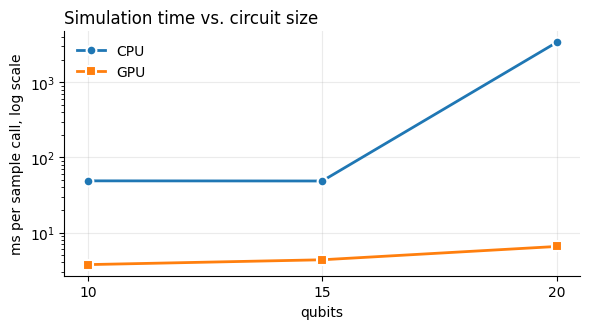

In [7]:
# Runtim comparison plot between CPU and GPU
MARKERS = {"CPU": "o", "GPU": "s", "multi-GPU": "^", "QPU": "D"}
fig, ax = plt.subplots(figsize=(6, 3.4))
for name, times in scaling.items():
    ax.plot(list(times), [t * 1e3 for t in times.values()], lw=2,
            marker=MARKERS[name], ms=7, markeredgecolor="white", markeredgewidth=1.5, label=name)
ax.set_yscale("log")
ax.set_xticks(SCALING_QUBITS)
ax.set_xlabel("qubits")
ax.set_ylabel("ms per sample call, log scale")
ax.set_title("Simulation time vs. circuit size", loc="left")
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

## Case 3: Multi-QPU Simulation on Multiple GPUs

With `option="mqpu"`, each GPU can act as a separate QPU.

- **Hamiltonian batching with MPI:** 4 MPI ranks, one GPU each.
- Every rank evaluates a quarter of the Hamiltonian's terms (`execution=cudaq.parallel.mpi`).

This needs several GPUs, so it runs only on the LRZ system (Colab might provide only one GPU).

In [ ]:
%%beast multi_gpu_mqpu --gpus 4 --mpi
# Hamiltonian batching: one MPI rank per GPU, the terms are split over the ranks
cudaq.mpi.initialize()
rank, n_ranks = cudaq.mpi.rank(), cudaq.mpi.num_ranks()
cudaq.set_target("nvidia", option="mqpu")
print(f"Rank {rank}/{n_ranks} on {socket.gethostname()}", flush=True)

@cudaq.kernel
def ghz_state(qubit_count: int):
    q = cudaq.qvector(qubit_count)
    h(q[0])
    for i in range(1, qubit_count):
        cx(q[0], q[i])

N_QUBITS, N_TERMS = 15, 100000
hamiltonian = cudaq.SpinOperator.random(N_QUBITS, N_TERMS, seed=13)   # same seed: same H on every rank
cudaq.observe(ghz_state, spin.z(0), N_QUBITS)                         # warm-up

if rank == 0:                                                         # baseline: one GPU
    t0 = time.perf_counter()
    e_1 = cudaq.observe(ghz_state, hamiltonian, N_QUBITS).expectation()
    t_1 = time.perf_counter() - t0

t0 = time.perf_counter()
e_n = cudaq.observe(ghz_state, hamiltonian, N_QUBITS,
                    execution=cudaq.parallel.mpi).expectation()      # terms split over all ranks
t_n = time.perf_counter() - t0

if rank == 0:
    print(f"{N_TERMS} terms on 1 GPU:          {t_1:.2f} s   <H> = {e_1:.6f}")
    print(f"{N_TERMS} terms on {n_ranks} GPUs (MPI): {t_n:.2f} s   <H> = {e_n:.6f}   speedup {t_1 / t_n:.1f}x")
cudaq.mpi.finalize()

ham_job = <MGPUJob 29383 4 GPU(s): QUEUED - waiting in the Slurm queue (Priority)>


In [ ]:
# On LRZ system, waits for the SLURM job to complete, then shows its output
print(multi_gpu_mqpu.result())

## Case 4: QPU

The cell below needs to run on real QPU. If you run the notebook on LRZ system, you do not need to enter the IQM token. Token and IQM QPU configuration are already done in the background.

If you run on Colab, please make sure to enter the IQM token at the cell on top.

The same `GHZ` runs on the IQM QPU. Each `sample` call is one job, so the time is mostly network and queueing, not the quantum run itself. Results also show hardware noise.

In [ ]:
%%beast iqm_qpu --gpus 0 --qpu iqm_eqe1
cudaq.set_target("iqm")
# Uncomment if running on Google Colab during the tutorial
# cudaq.set_target("iqm",use_timeslot=True)
counts, seconds = sample_ghz_state(5, SHOTS)
print(counts)
with open("output/qpu.json", "w") as f:
    json.dump({"counts": dict(counts.items()), "seconds": seconds}, f)

{ 00000:356 00001:50 00010:32 00011:4 00100:18 00101:4 00110:24 00111:5 01000:35 01001:13 01010:1 01011:2 01100:2 01101:1 01110:10 01111:21 10000:2 10001:7 10011:3 10100:1 10101:7 10110:9 10111:42 11000:1 11001:7 11010:7 11011:29 11100:1 11101:15 11110:35 11111:256 }



In [ ]:
# On LRZ system, waits for the SLURM job to complete, then shows its output
print(iqm_qpu.result())
with open(iqm_qpu.files[0]) as f:
    data = json.load(f)
ghz["QPU"] = (data["counts"], data["seconds"])

## Summary

The left plot shows that every backend returns the expected result, up to shot noise and, on the QPU, hardware noise. The right plot shows what the same sweep costs on each backend.

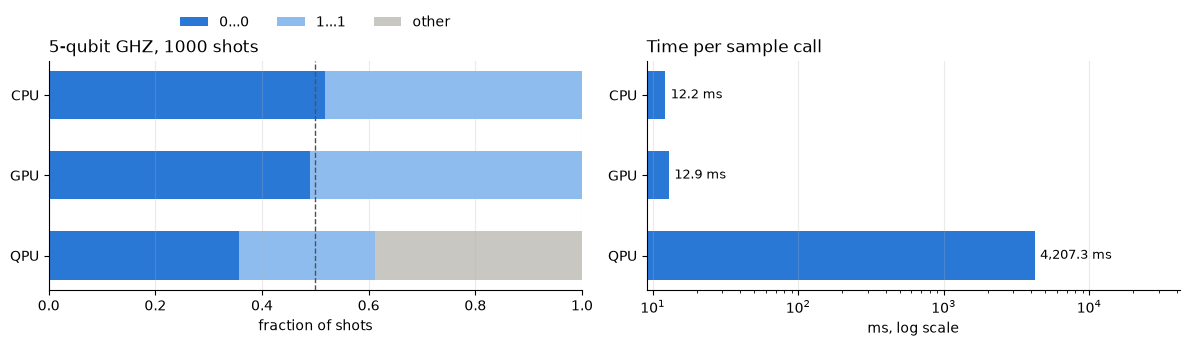

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))

names = list(ghz)
n_qubits = len(next(iter(ghz[names[0]][0])))        # GHZ size, read from a bitstring

# Left: where the shots landed. Ideal GHZ = 50% |0...0>, 50% |1...1>, 0% other
probs = []
for n in names:
    counts = dict(ghz[n][0].items())               # CUDA-Q result or dict from a job
    zeros = counts.get("0" * n_qubits, 0) / SHOTS
    ones = counts.get("1" * n_qubits, 0) / SHOTS
    probs.append((zeros, ones, 1 - zeros - ones))
probs = np.array(probs)

left = np.zeros(len(names))
for col, (label, color) in enumerate([("0...0", "#2a78d6"), ("1...1", "#8fbcef"), ("other", "#c9c7c1")]):
    ax1.barh(names, probs[:, col], left=left, color=color, height=0.6, label=label)
    left += probs[:, col]
ax1.axvline(0.5, color="#52514e", lw=1, ls="--")
ax1.invert_yaxis()
ax1.set_xlim(0, 1)
ax1.set_xlabel("fraction of shots")
ax1.set_title(f"{n_qubits}-qubit GHZ, {SHOTS} shots", loc="left")
ax1.legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.08))

# Right: time of one sample call per backend
ms = [ghz[n][1] * 1e3 for n in names]
ax2.barh(names, ms, color="#2a78d6", height=0.6)
for y, v in enumerate(ms):
    ax2.annotate(f"{v:,.1f} ms", (v, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
ax2.invert_yaxis()
ax2.set_xscale("log")
ax2.set_xlim(right=max(ms) * 10)    # room for the value labels
ax2.set_xlabel("ms, log scale")
ax2.set_title("Time per sample call", loc="left")

for ax in (ax1, ax2):
    ax.grid(alpha=0.25, axis="x")
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

**Takeaways**

- The same kernel runs in all four cases. Only `cudaq.set_target` changes.
- **CPU:** fastest for small circuits.
- **GPU:** pays off as the qubit count grows.
- **Multi-GPU for Multi-QPU simulation:** increases throughput when there are many circuits.
- **QPU:** time is mostly communication and queueing. That latency is what tighter GPU–QPU coupling such as NVQLink aims to reduce.